In [1]:
import numpy as np
import pandas as pd
from matplotlib import pyplot as plt
import seaborn as sns
import random
import types

from time import time

from scipy.special import comb, loggamma, lambertw
from scipy.stats import multinomial, expon

from silence_tensorflow import silence_tensorflow
silence_tensorflow()
import tensorflow as tf
import tensorflow_probability as tfp
from tensorflow import keras
from tensorflow.keras import optimizers, initializers, regularizers, layers

config = tf.compat.v1.ConfigProto()
config.gpu_options.allow_growth = True
sess = tf.compat.v1.Session(config = config)

import os, shutil
from pathlib import Path
import json
import subprocess

import sys
sys.path.insert(0, "../src")
from package import cure_aft
from package import gndr_utils as utils

import thetaflow as thf

E0000 00:00:1792701053.250882   12985 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1792701053.258089   12985 cuda_blas.cc:1407] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
W0000 00:00:1792701053.276129   12985 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1792701053.276160   12985 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1792701053.276163   12985 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1792701053.276165   12985 computation_placer.cc:177] computation placer already registered. Please check linka

## Loading data

In [2]:
df_train = pd.read_csv("../data/01_mlready/metabric_train.csv")
df_test = pd.read_csv("../data/01_mlready/metabric_test.csv")

print("Train data dimension: {}".format(df_train.shape))
print("Test data dimension: {}".format(df_test.shape))

df_train.head()

Train data dimension: (1386, 183)
Test data dimension: (463, 183)


,patient_id,time,delta,age_at_diagnosis,npi,pam50_subtype_Basal,pam50_subtype_Her2,pam50_subtype_LumB,pam50_subtype_Normal,pam50_subtype_claudin-low,...,NT5E,NRAS,CCND3,AGTR2,MBL2,SIAH1,STMN2,RASGEF1B,SMARCB1,HRAS
0,MB-6359,71.533333,1.0,0.946643,-0.883129,0.0,1.0,0.0,0.0,0.0,...,0,0,0,1,0,0,0,0,0,0
1,MB-4357,113.866667,1.0,1.231628,0.879891,0.0,0.0,0.0,0.0,0.0,...,0,0,0,0,0,0,0,0,0,0
2,MB-5530,185.933333,0.0,-0.810247,0.888724,1.0,0.0,0.0,0.0,0.0,...,0,0,0,0,0,0,0,0,0,0
3,MB-5451,189.900000,0.0,-1.362501,-0.895495,0.0,0.0,0.0,0.0,0.0,...,0,0,0,0,0,0,0,0,0,0
4,MB-0481,33.866667,1.0,-0.532195,-0.005152,1.0,0.0,0.0,0.0,0.0,...,0,0,0,0,0,0,0,0,0,0


In [3]:
# Lifetimes and censoring indicators
y_train = df_train["time"]
delta_train = df_train["delta"]
# Data for the neural network interpreter
X_train_nn = df_train.iloc[:, 10:]
# For all parameters from the AFT mNoneodel, consider the same set of features as predictors
z_train_mu = df_train.iloc[:, 3:10]
z_train_sigma = df_train.iloc[:, 3:10]
z_train_p = df_train.iloc[:, 3:10]


# Lifetimes and censoring indicators
y_test = df_test["time"]
delta_test = df_test["delta"]
# Data for the neural network interpreter
X_test_nn = df_test.iloc[:, 10:]
# For all parameters from the AFT model, consider the same set of features as predictors
z_test_mu = df_test.iloc[:, 3:10]
z_test_sigma = df_test.iloc[:, 3:10]
z_test_p = df_test.iloc[:, 3:10]

## Definição da arquitetura da rede neural

In [4]:
def cure_aft_neural_network1(model, seed = None):
    initializer = initializers.GlorotNormal(seed=seed)
    
    # Penalizador para pesos muito grandes
    l2_reg = regularizers.l2(0.01)

    # Camada de Embedding Compartilhada
    # Transforma contagens (0, 1, 2, 3) em embeddings de 2 dimensões
    model.embedding = keras.layers.Embedding(
        input_dim = 4, 
        output_dim = 2, 
        name = "embedding_compartilhado"
    )
    
    # Flatten para conectar à rede densa - 346 entradas
    model.flatten = keras.layers.Flatten(name = "flatten_mutacoes")

    # Camada oculta densa 1
    model.dense1 = keras.layers.Dense(
        units = 64, activation = "gelu", kernel_initializer = initializer, 
        kernel_regularizer = l2_reg, dtype = tf.float32, name = "dense1"
    )
    model.bn1 = keras.layers.BatchNormalization(name = "bn1")
    model.dropout1 = keras.layers.Dropout(rate = 0.4, seed = seed, name = "drop1")

    # Camada oculta densa 2
    model.dense2 = keras.layers.Dense(
        units = 32, activation = "gelu", kernel_initializer = initializer,
        kernel_regularizer = l2_reg, dtype = tf.float32, name = "dense2"
    )
    model.bn2 = keras.layers.BatchNormalization(name = "bn2")
    model.dropout2 = keras.layers.Dropout(rate = 0.3, seed=seed, name = "drop2")

    # Camada oculta densa 3
    model.dense3 = keras.layers.Dense(
        units = 16, activation = "gelu", kernel_initializer = initializer, 
        dtype = tf.float32, name = "dense3"
    )
    
    # Camada de saída
    model.dense4 = keras.layers.Dense(
        units = 1, kernel_initializer = initializer, dtype = tf.float32, 
        activation = None, use_bias = True, name = "output"
    )

def cure_aft_neural_network2(model, seed = None):
    initializer = initializers.GlorotNormal(seed=seed)
    
    # Penalizador para pesos muito grandes
    l2_reg = regularizers.l2(0.01)

    # Camada de Embedding Compartilhada
    # Transforma contagens (0, 1, 2, 3) em embeddings de 2 dimensões
    model.embedding = keras.layers.Embedding(
        input_dim = 4, 
        output_dim = 2, 
        name = "embedding_compartilhado"
    )
    
    # Flatten para conectar à rede densa - 346 entradas
    model.flatten = keras.layers.Flatten(name = "flatten_mutacoes")

    # Camada oculta densa 1
    model.dense1 = keras.layers.Dense(
        units = 64, activation = "gelu", kernel_initializer = initializer, 
        kernel_regularizer = l2_reg, dtype = tf.float32, name = "dense1"
    )
    model.bn1 = keras.layers.BatchNormalization(name = "bn1")
    model.dropout1 = keras.layers.Dropout(rate = 0.4, seed = seed, name = "drop1")

    # Camada oculta densa 2
    model.dense2 = keras.layers.Dense(
        units = 32, activation = "gelu", kernel_initializer = initializer,
        kernel_regularizer = l2_reg, dtype = tf.float32, name = "dense2"
    )
    model.bn2 = keras.layers.BatchNormalization(name = "bn2")
    model.dropout2 = keras.layers.Dropout(rate = 0.3, seed=seed, name = "drop2")

    # Camada oculta densa 3
    model.dense3 = keras.layers.Dense(
        units = 16, activation = "gelu", kernel_initializer = initializer, 
        dtype = tf.float32, name = "dense3"
    )
    
    # Camada de saída
    model.dense4 = keras.layers.Dense(
        units = 2, kernel_initializer = initializer, dtype = tf.float32, 
        activation = None, use_bias = True, name = "output"
    )

def cure_aft_network_call(model, x_input, training=False):
    # Passagem do embedding e achatamento
    x = model.embedding(x_input)
    x = model.flatten(x)
    
    # Passagem pelo Bloco 1 (com flag training para o BN e Dropout agirem apenas no treino)
    x = model.dense1(x)
    x = model.bn1(x, training=training)
    x = model.dropout1(x, training=training)
    
    # Passagem pelo Bloco 2
    x = model.dense2(x)
    x = model.bn2(x, training=training)
    x = model.dropout2(x, training=training)
    
    # Passagem pelo Bloco 3 e Saída
    x = model.dense3(x)
    return model.dense4(x)

def cure_aft_network_call_nolast(model, x_input, training=False):
    x = model.embedding(x_input)
    x = model.flatten(x)
    
    x = model.dense1(x)
    x = model.bn1(x, training=training)
    x = model.dropout1(x, training=training)
    
    x = model.dense2(x)
    x = model.bn2(x, training=training)
    x = model.dropout2(x, training=training)
    
    x = model.dense3(x)
    return x

## Definição e treinamento do modelo

In [5]:
def train_model( model_parameters, model_loss, nn_arch, nn_call, nn_call_nolast, X_train_nn, data_train, epochs = 15000 ):
    with tf.device("/CPU:0"):
        if(X_train_nn is not None):
            model = thf.ModelNN(model_parameters, model_loss,
                                nn_arch, nn_call, nn_call_nolast,
                                input_dim = (X_train_nn.shape[1], ), seed = 10)
        else:
            model = thf.ModelNN(model_parameters, model_loss,
                                nn_arch, nn_call, nn_call_nolast, seed = 10)
        if(model.neural_network_use):
            model.pre_train_model(epochs = epochs, x = X_train_nn, data = data_train)
        model.train_model(epochs = epochs, x = X_train_nn, data = data_train,
                          shuffle = True,
                          get_covariances = True,
                          validation = True, val_prop = 0.2, force_training_validation = False,
                          optimizer_independent = optimizers.Adam(learning_rate = 0.01),
                          optimizer_nn = optimizers.Adam(learning_rate = 0.01),
                          fine_tune_nn_lr = 0.01, fine_tune_independent_lr = 0.01,
                          early_stopping = True, early_stopping_patience = 50, 
                          early_stopping_warmup = 10, early_stopping_min_delta = 1.0e-3,
                          reduce_lr = True, reduce_lr_warmup = 0,
                          reduce_lr_factor = 0.5, reduce_lr_min_delta = 1.0e-3, reduce_lr_patience = 25,
                          reduce_lr_cooldown = 10, reduce_lr_min_lr = 1.0e-5,
                          fine_tune = True,
                          finetune_early_stopping = True, finetune_early_stopping_patience = 50,
                          finetune_early_stopping_warmup = 10, finetune_early_stopping_min_delta = 1.0e-2,
                          finetune_reduce_lr = True, finetune_reduce_lr_warmup = 0,
                          finetune_reduce_lr_factor = 0.5, finetune_reduce_lr_min_delta = 1.0e-2, finetune_reduce_lr_patience = 25,
                          finetune_reduce_lr_cooldown = 10, finetune_reduce_lr_min_lr = 1.0e-5,
                          deterministic = True,
                          verbose = True, print_freq = 1)
    return model

In [50]:
wb_parameters, wb_loss, wb_survival_cure = cure_aft.build_cure_aft_structure4("wb", z_train_mu, z_train_sigma, z_train_p)
ln_parameters, ln_loss, ln_survival_cure = cure_aft.build_cure_aft_structure4("ln", z_train_mu, z_train_sigma, z_train_p)
ll_parameters, ll_loss, ll_survival_cure = cure_aft.build_cure_aft_structure4("ll", z_train_mu, z_train_sigma, z_train_p)
# gg_parameters, gg_loss = cure_aft.build_cure_aft_structure3("wb", z_train_mu, z_train_sigma, z_train_p)

data_train = [z_train_mu, z_train_sigma, z_train_p, y_train, delta_train]
data_test = [z_test_mu, z_test_sigma, z_test_p, y_test, delta_test]

In [51]:
wb_model = train_model( wb_parameters, wb_loss, cure_aft_neural_network2, cure_aft_network_call, cure_aft_network_call_nolast, X_train_nn, data_train )

Global seed set to 10.
Initializing training...
Optimizing... Epoch: [ 156 / 15000 ]  | Avg. Train NLL:  2.75742388 | Avg. Validation NLL:  2.93618822 | Best Avg. Validation NLL:  2.79992723 | Speed:  0.04893234  epoch/s    | Elapsed Time:  7.63344526  s     
Convergence criterion reached. Stopping.
Optimizing... Epoch: [ 157 / 15000 ]  | Avg. Train NLL:  2.75948334 | Avg. Validation NLL:  2.93901396 | Best Avg. Validation NLL:  2.79992723 | Speed:  0.0489361957  epoch/s    | Elapsed Time:  7.68298292  s   Restoring best weights...

Done.
Initializing model fine tuning (only independent parameters and last-layer)
Optimizing... Epoch: [ 4995 / 15000 ]  | Avg. Train NLL:  2.45674777 | Best Avg. Train NLL:  2.45674777 | Avg. Validation NLL:  3.10067844 | Speed:  0.0127967447  epoch/s    | Elapsed Time:  63.9197388  s   
Convergence criterion reached. Stopping.
Restoring best weights...

Done.
Extracting covariance structure.
Done.
Optimization finished in 91.437 seconds.


In [52]:
wb_model = thf.ModelNN(wb_parameters, wb_loss,
                       cure_aft_neural_network, cure_aft_network_call, cure_aft_network_call_nolast,
                       input_dim = (X_train_nn.shape[1], ), seed = 10)

wb_model.load_model("../model_weights/Structure4/wb_model")

Model successfully loaded from ../model_weights/Structure4/wb_model.


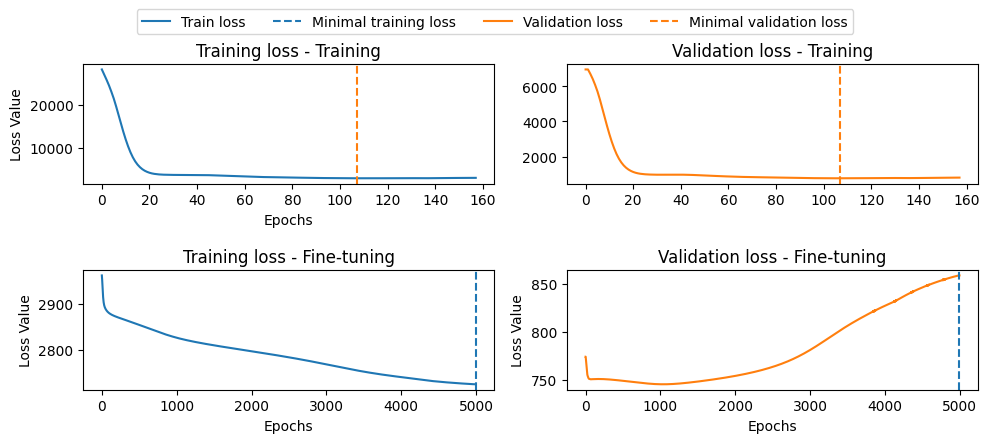

In [53]:
utils.plot_model_convergence( wb_model, figsize = (10,4) )

In [12]:
ln_model = train_model(ln_parameters, ln_loss, cure_aft_neural_network2, cure_aft_network_call, cure_aft_network_call_nolast, X_train_nn, data_train )
ln_model_restricted = train_model(ln_parameters, ln_loss, cure_aft_neural_network2, cure_aft_network_call, cure_aft_network_call_nolast, X_train_nn, data_train,
                                  epochs = 3700)

Global seed set to 10.
Initializing training...
Optimizing... Epoch: [ 112 / 15000 ]  | Avg. Train NLL:  3.14463043 | Avg. Validation NLL:  3.42680144 | Best Avg. Validation NLL:  2.8154912 | Speed:  0.0278224628  epoch/s    | Elapsed Time:  3.11611581  s    
Convergence criterion reached. Stopping.
Optimizing... Epoch: [ 113 / 15000 ]  | Avg. Train NLL:  3.15573311 | Avg. Validation NLL:  3.43891239 | Best Avg. Validation NLL:  2.8154912 | Speed:  0.027768841  epoch/s    | Elapsed Time:  3.13787913  s   Restoring best weights...

Done.
Initializing model fine tuning (only independent parameters and last-layer)
Optimizing... Epoch: [ 5413 / 15000 ]  | Avg. Train NLL:  -36.8167152 | Best Avg. Train NLL:  -36.8167152 | Avg. Validation NLL:  -35.6430893 | Speed:  0.00927198213  epoch/s    | Elapsed Time:  50.1892395  s      
Convergence criterion reached. Stopping.
Restoring best weights...

Done.
Extracting covariance structure.


/home/natan/.pyenv/versions/3.11.10/lib/python3.11/site-packages/thetaflow/modelnn.py:2609: RuntimeWarning: Covariance matrix could not be computed because the loss function does not depend on:
['p_beta[0]', 'p_beta[1]', 'p_beta[2]', 'p_beta[3]', 'p_beta[4]', 'p_beta[5]', 'p_beta[6]', 'p_nn']
Please, double check your loss function definition.
  warnings.warn(


Done.
Optimization finished in 67.617 seconds.
Global seed set to 10.
Initializing training...
Optimizing... Epoch: [ 112 / 3700 ]  | Avg. Train NLL:  3.14463043 | Avg. Validation NLL:  3.42680144 | Best Avg. Validation NLL:  2.8154912 | Speed:  0.0295362808  epoch/s    | Elapsed Time:  3.30806351  s    
Convergence criterion reached. Stopping.
Optimizing... Epoch: [ 113 / 3700 ]  | Avg. Train NLL:  3.15573311 | Avg. Validation NLL:  3.43891239 | Best Avg. Validation NLL:  2.8154912 | Speed:  0.0294644646  epoch/s    | Elapsed Time:  3.32948446  s   Restoring best weights...

Done.
Initializing model fine tuning (only independent parameters and last-layer)
Optimizing... Epoch: [ 3699 / 3700 ]  | Avg. Train NLL:  2.39578533 | Best Avg. Train NLL:  2.39578533 | Avg. Validation NLL:  3.0494678 | Speed:  0.00930361263  epoch/s    | Elapsed Time:  34.4140625  s    
Done.
Extracting covariance structure.
Done.
Optimization finished in 51.150 seconds.


In [9]:
ln_model = thf.ModelNN(ln_parameters, ln_loss,
                       cure_aft_neural_network, cure_aft_network_call, cure_aft_network_call_nolast,
                       input_dim = (X_train_nn.shape[1], ), seed = 10)
ln_model_restricted = thf.ModelNN(ln_parameters, ln_loss,
                                  cure_aft_neural_network, cure_aft_network_call, cure_aft_network_call_nolast,
                                  input_dim = (X_train_nn.shape[1], ), seed = 10)

ln_model.load_model("../model_weights/Structure4/ln_model")
ln_model_restricted.load_model("../model_weights/Structure4/ln_model_restricted")

Model successfully loaded from ../model_weights/Structure4/ln_model.
Model successfully loaded from ../model_weights/Structure4/ln_model_restricted.


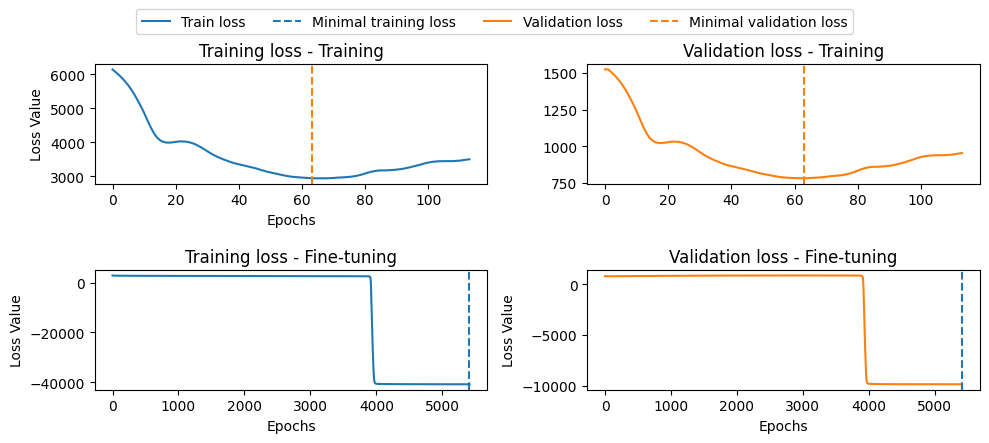

In [10]:
utils.plot_model_convergence( ln_model, figsize = (10,4) )

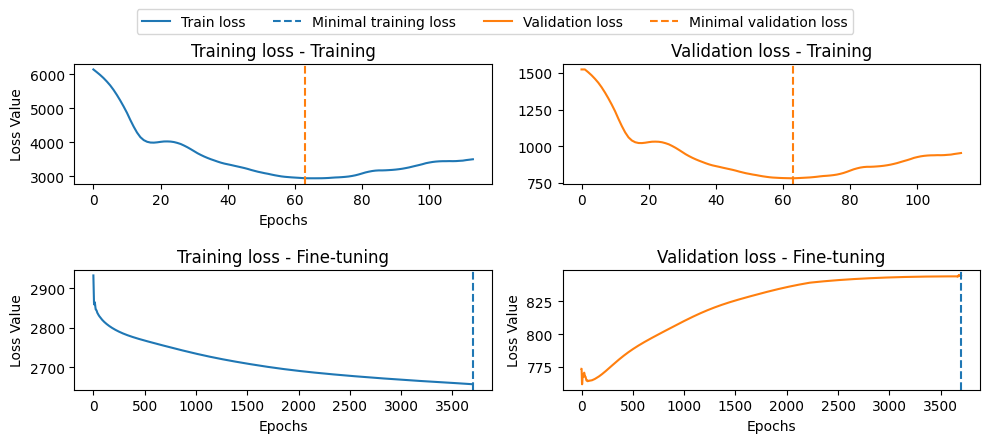

In [11]:
utils.plot_model_convergence( ln_model_restricted, figsize = (10,4) )

In [11]:
ll_model = train_model(ll_parameters, ll_loss, cure_aft_neural_network2, cure_aft_network_call, cure_aft_network_call_nolast, X_train_nn, data_train)
ll_model_restricted = train_model(ll_parameters, ll_loss, cure_aft_neural_network2, cure_aft_network_call, cure_aft_network_call_nolast, X_train_nn, data_train,
                                  epochs = 3000)

Global seed set to 10.
Initializing training...
Optimizing... Epoch: [ 104 / 15000 ]  | Avg. Train NLL:  2.67086554 | Avg. Validation NLL:  2.7157774 | Best Avg. Validation NLL:  2.69935298 | Speed:  0.0229454171  epoch/s    | Elapsed Time:  2.38632345  s    
Convergence criterion reached. Stopping.
Optimizing... Epoch: [ 105 / 15000 ]  | Avg. Train NLL:  2.62593579 | Avg. Validation NLL:  2.70491529 | Best Avg. Validation NLL:  2.69935298 | Speed:  0.0230802596  epoch/s    | Elapsed Time:  2.42342734  s   Restoring best weights...

Done.
Initializing model fine tuning (only independent parameters and last-layer)
Optimizing... Epoch: [ 6192 / 15000 ]  | Avg. Train NLL:  -36.9139442 | Best Avg. Train NLL:  -36.9139442 | Avg. Validation NLL:  -35.5817375 | Speed:  0.00853571203  epoch/s    | Elapsed Time:  52.8531265  s     
Convergence criterion reached. Stopping.
Restoring best weights...

Done.
Extracting covariance structure.


/home/natan/.pyenv/versions/3.11.10/lib/python3.11/site-packages/thetaflow/modelnn.py:2609: RuntimeWarning: Covariance matrix could not be computed because the loss function does not depend on:
['p_beta[3]', 'p_beta[4]', 'p_beta[5]', 'p_beta[6]']
Please, double check your loss function definition.
  warnings.warn(


Done.
Optimization finished in 64.942 seconds.
Global seed set to 10.
Initializing training...
Optimizing... Epoch: [ 104 / 3000 ]  | Avg. Train NLL:  2.67086554 | Avg. Validation NLL:  2.7157774 | Best Avg. Validation NLL:  2.69935298 | Speed:  0.0286117233  epoch/s    | Elapsed Time:  2.97561932  s    
Convergence criterion reached. Stopping.
Optimizing... Epoch: [ 105 / 3000 ]  | Avg. Train NLL:  2.62593579 | Avg. Validation NLL:  2.70491529 | Best Avg. Validation NLL:  2.69935298 | Speed:  0.0285498332  epoch/s    | Elapsed Time:  2.9977324  s   Restoring best weights...

Done.
Initializing model fine tuning (only independent parameters and last-layer)
Optimizing... Epoch: [ 2999 / 3000 ]  | Avg. Train NLL:  2.45159411 | Best Avg. Train NLL:  2.45159411 | Avg. Validation NLL:  2.87765408 | Speed:  0.0101450142  epoch/s    | Elapsed Time:  30.4248981  s    
Done.
Extracting covariance structure.
Done.
Optimization finished in 46.322 seconds.


In [12]:
ll_model = thf.ModelNN(ll_parameters, ll_loss,
                       cure_aft_neural_network, cure_aft_network_call, cure_aft_network_call_nolast,
                       input_dim = (X_train_nn.shape[1], ), seed = 10)
ll_model_restricted = thf.ModelNN(ll_parameters, ll_loss,
                                  cure_aft_neural_network, cure_aft_network_call, cure_aft_network_call_nolast,
                                  input_dim = (X_train_nn.shape[1], ), seed = 10)

ll_model.load_model("../model_weights/Structure4/ll_model")
ll_model_restricted.load_model("../model_weights/Structure4/ll_model_restricted")

Model successfully loaded from ../model_weights/Structure4/ll_model.
Model successfully loaded from ../model_weights/Structure4/ll_model_restricted.


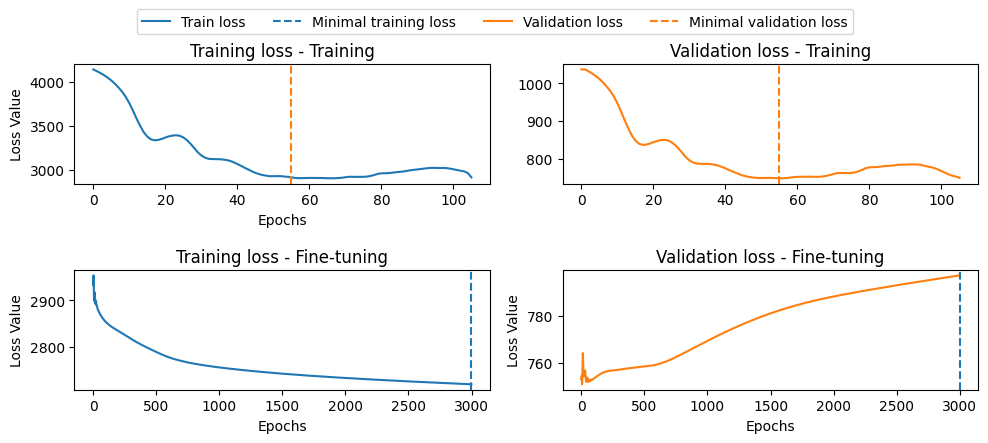

In [13]:
utils.plot_model_convergence( ll_model_restricted, figsize = (10,4) )

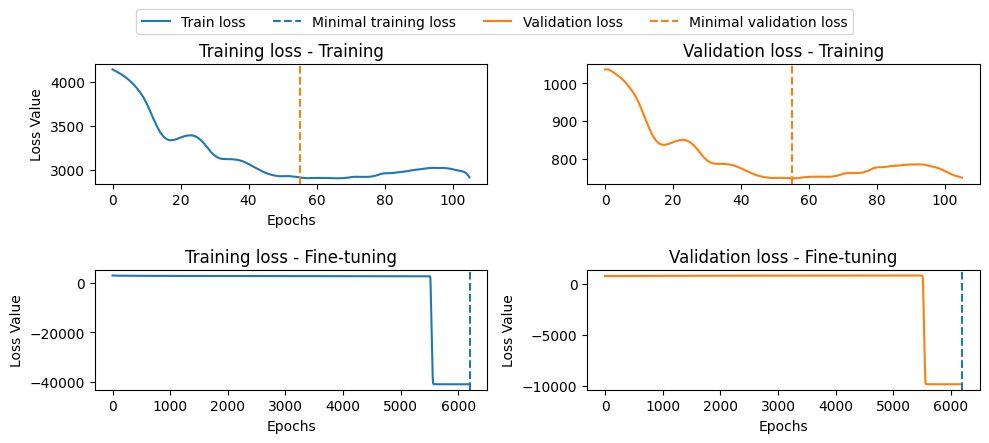

In [14]:
utils.plot_model_convergence( ll_model, figsize = (10,4) )

In [15]:
wb_summary = wb_survival_cure(wb_model,
                              y_train, delta_train, X_train_nn, z_train_mu, z_train_sigma, z_train_p,
                              y_test, delta_test, X_test_nn, z_test_mu, z_test_sigma, z_test_p, ngrid = 100)

ln_summary = ln_survival_cure(ln_model,
                              y_train, delta_train, X_train_nn, z_train_mu, z_train_sigma, z_train_p,
                              y_test, delta_test, X_test_nn, z_test_mu, z_test_sigma, z_test_p, ngrid = 100)
ln_summary_restricted = ln_survival_cure(ln_model_restricted,
                              y_train, delta_train, X_train_nn, z_train_mu, z_train_sigma, z_train_p,
                              y_test, delta_test, X_test_nn, z_test_mu, z_test_sigma, z_test_p, ngrid = 100)

ll_summary = ll_survival_cure(ll_model,
                              y_train, delta_train, X_train_nn, z_train_mu, z_train_sigma, z_train_p,
                              y_test, delta_test, X_test_nn, z_test_mu, z_test_sigma, z_test_p, ngrid = 100)
ll_summary_restricted = ll_survival_cure(ll_model_restricted,
                                         y_train, delta_train, X_train_nn, z_train_mu, z_train_sigma, z_train_p,
                                         y_test, delta_test, X_test_nn, z_test_mu, z_test_sigma, z_test_p, ngrid = 100)

In [15]:
wb_model.save_model("../model_weights/Structure3/wb_model")
ln_model.save_model("../model_weights/Structure3/ln_model")
ln_model_restricted.save_model("../model_weights/Structure3/ln_model_restricted")
ll_model.save_model("../model_weights/Structure3/ll_model")
ll_model_restricted.save_model("../model_weights/Structure3/ll_model_restricted")

Model successfully saved to ../model_weights/wb_model.weights.h5 and ../model_weights/wb_model_meta.pkl
Model successfully saved to ../model_weights/ln_model.weights.h5 and ../model_weights/ln_model_meta.pkl
Model successfully saved to ../model_weights/ln_model_restricted.weights.h5 and ../model_weights/ln_model_restricted_meta.pkl
Model successfully saved to ../model_weights/ll_model.weights.h5 and ../model_weights/ll_model_meta.pkl
Model successfully saved to ../model_weights/ll_model_restricted.weights.h5 and ../model_weights/ll_model_restricted_meta.pkl


In [16]:
def parameters_histogram(model_summary, figsize = (12,4)):
    fig, ax = plt.subplots(nrows = 1, ncols = 3, figsize = figsize)

    sns.histplot(x = model_summary["mu_train"], ax = ax[0])
    sns.histplot(x = model_summary["sigma_train"], ax = ax[1])
    sns.histplot(x = model_summary["p_train"], ax = ax[2])

    ax[0].set_title("mu - Train")
    ax[1].set_title("sigma - Train")
    ax[2].set_title("p - Train")

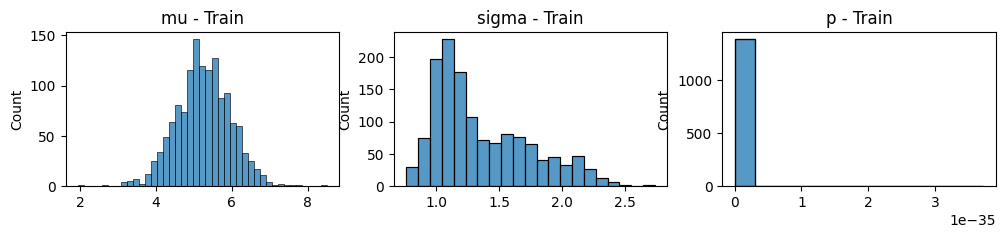

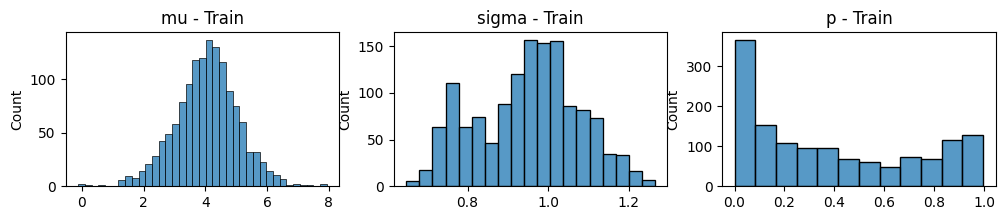

In [17]:
parameters_histogram(ln_summary, figsize = (12,2))
parameters_histogram(ln_summary_restricted, figsize = (12,2))

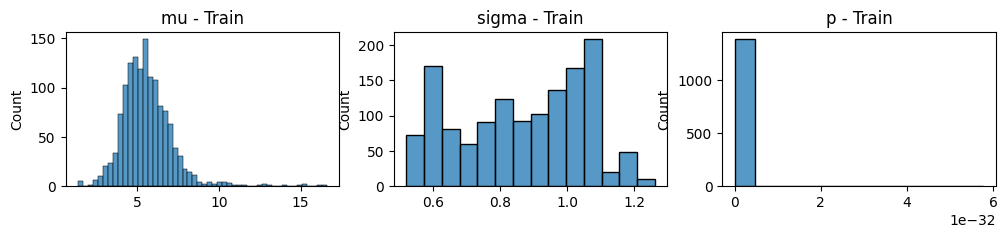

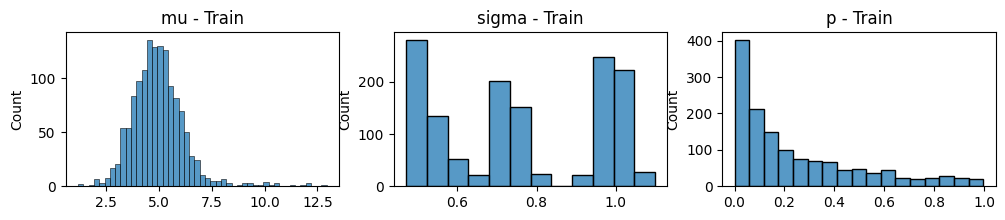

In [18]:
parameters_histogram(ll_summary, figsize = (12,2))
parameters_histogram(ll_summary_restricted, figsize = (12,2))

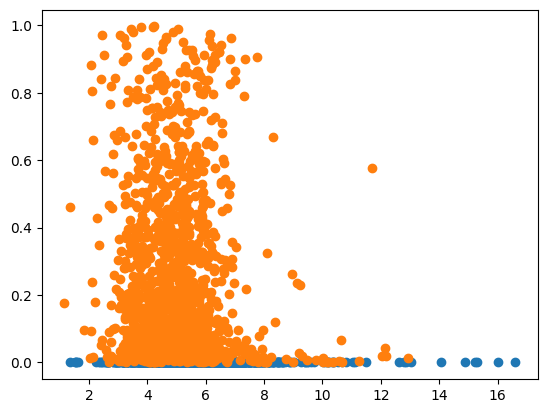

In [19]:
ll_p_train = ll_summary["p_train"]
ll_mu_train = ll_summary["mu_train"]
ll_restricted_p_train = ll_summary_restricted["p_train"]
ll_restricted_mu_train = ll_summary_restricted["mu_train"]

plt.plot(ll_mu_train, ll_p_train, "o", label = "Log-logistic")
plt.plot(ll_restricted_mu_train, ll_restricted_p_train, "o", label = "Log-logistic restricted")
plt.show()

The phenomenon above is interesting and may be caused by an implementation error or it may be intrinsically associated with an identifiability problem in our model assumptions. Given the flexibility of the Log-normal and the Log-logistic distributions with respect to their tails, it may be possible that the model learns that it is more reasonable to assume all patients to be susceptible and make their lifetime distribution tails heavier, simulating a virtual cure fraction.

### Peparing different model structures

In [32]:
wb_parameters1, wb_loss1, wb_survival_cure1 = cure_aft.build_cure_aft_structure1("wb", z_train_mu, z_train_sigma, z_train_p)
ln_parameters1, ln_loss1, ln_survival_cure1 = cure_aft.build_cure_aft_structure1("ln", z_train_mu, z_train_sigma, z_train_p)
ll_parameters1, ll_loss1, ll_survival_cure1 = cure_aft.build_cure_aft_structure1("ll", z_train_mu, z_train_sigma, z_train_p)

wb_parameters2, wb_loss2, wb_survival_cure2 = cure_aft.build_cure_aft_structure2("wb", z_train_mu, z_train_sigma, z_train_p)
ln_parameters2, ln_loss2, ln_survival_cure2 = cure_aft.build_cure_aft_structure2("ln", z_train_mu, z_train_sigma, z_train_p)
ll_parameters2, ll_loss2, ll_survival_cure2 = cure_aft.build_cure_aft_structure2("ll", z_train_mu, z_train_sigma, z_train_p)

wb_parameters3, wb_loss3, wb_survival_cure3 = cure_aft.build_cure_aft_structure3("wb", z_train_mu, z_train_sigma, z_train_p)
ln_parameters3, ln_loss3, ln_survival_cure3 = cure_aft.build_cure_aft_structure3("ln", z_train_mu, z_train_sigma, z_train_p)
ll_parameters3, ll_loss3, ll_survival_cure3 = cure_aft.build_cure_aft_structure3("ll", z_train_mu, z_train_sigma, z_train_p)

wb_parameters4, wb_loss4, wb_survival_cure4 = cure_aft.build_cure_aft_structure4("wb", z_train_mu, z_train_sigma, z_train_p)
ln_parameters4, ln_loss4, ln_survival_cure4 = cure_aft.build_cure_aft_structure4("ln", z_train_mu, z_train_sigma, z_train_p)
ll_parameters4, ll_loss4, ll_survival_cure4 = cure_aft.build_cure_aft_structure4("ll", z_train_mu, z_train_sigma, z_train_p)

data_train = [z_train_mu, z_train_sigma, z_train_p, y_train, delta_train]
data_test = [z_test_mu, z_test_sigma, z_test_p, y_test, delta_test]

In [7]:
def train_save_model(model_parameters, model_loss, nn_arch, nn_call, nn_call_nolast, X_train_nn, data_train, structure, filename, epochs = 15000):
    model = train_model( model_parameters, model_loss, nn_arch, nn_call, nn_call_nolast, X_train_nn, data_train, epochs = epochs )
    model.save_model("../model_weights/Structure{}/{}".format(structure, filename))
    print("Successfully saved file Structure{}/{}\n".format(structure, filename))

### Structure 1

In [9]:
train_save_model(wb_parameters1, wb_loss1, None, None, None,
                 None, data_train,
                 1, "wb_model", epochs = 15000)
train_save_model(ln_parameters1, ln_loss1, None, None, None,
                 None, data_train,
                 1, "ln_model", epochs = 15000)
train_save_model(ll_parameters1, ll_loss1, None, None, None,
                 None, data_train,
                 1, "ll_model", epochs = 15000)

Global seed set to 10.
Initializing training...
Optimizing... Epoch: [ 381 / 15000 ]  | Avg. Train NLL:  8.24940205 | Avg. Validation NLL:  8.05171394 | Best Avg. Validation NLL:  7.9960885 | Speed:  0.00347620412  epoch/s    | Elapsed Time:  1.3244338  s      
Convergence criterion reached. Stopping.
Optimizing... Epoch: [ 382 / 15000 ]  | Avg. Train NLL:  8.24763107 | Avg. Validation NLL:  8.05328941 | Best Avg. Validation NLL:  7.9960885 | Speed:  0.00348301837  epoch/s    | Elapsed Time:  1.330513  s   Restoring best weights...

Done.
Extracting covariance structure.
Done.
Optimization finished in 10.901 seconds.
Model successfully saved to ../model_weights/Structure1/wb_model.weights.h5 and ../model_weights/Structure1/wb_model_meta.pkl
Successfully saved file Structure1/wb_model

Global seed set to 10.
Initializing training...
Optimizing... Epoch: [ 585 / 15000 ]  | Avg. Train NLL:  3.81481767 | Avg. Validation NLL:  3.69365835 | Best Avg. Validation NLL:  3.69361258 | Speed:  0.0

### Structure 2

In [10]:
train_save_model(wb_parameters2, wb_loss2, cure_aft_neural_network1, cure_aft_network_call, cure_aft_network_call_nolast,
                 X_train_nn, data_train,
                 2, "wb_model", epochs = 15000)
train_save_model(ln_parameters2, ln_loss2, cure_aft_neural_network1, cure_aft_network_call, cure_aft_network_call_nolast,
                 X_train_nn, data_train,
                 2, "ln_model", epochs = 15000)
train_save_model(ll_parameters2, ll_loss2, cure_aft_neural_network1, cure_aft_network_call, cure_aft_network_call_nolast,
                 X_train_nn, data_train,
                 2, "ll_model", epochs = 15000)

Global seed set to 10.
Initializing training...
Optimizing... Epoch: [ 187 / 15000 ]  | Avg. Train NLL:  2.66719365 | Avg. Validation NLL:  2.73421979 | Best Avg. Validation NLL:  2.69933867 | Speed:  0.0217528474  epoch/s    | Elapsed Time:  4.0677824  s    
Convergence criterion reached. Stopping.
Optimizing... Epoch: [ 188 / 15000 ]  | Avg. Train NLL:  2.6678946 | Avg. Validation NLL:  2.73489165 | Best Avg. Validation NLL:  2.69933867 | Speed:  0.0217528418  epoch/s    | Elapsed Time:  4.08953428  s   Restoring best weights...

Done.
Initializing model fine tuning (only independent parameters and last-layer)
Optimizing... Epoch: [ 3027 / 15000 ]  | Avg. Train NLL:  2.56627274 | Best Avg. Train NLL:  2.56627274 | Avg. Validation NLL:  2.70968199 | Speed:  0.00852774084  epoch/s    | Elapsed Time:  25.8134708  s   
Convergence criterion reached. Stopping.
Restoring best weights...

Done.
Extracting covariance structure.
Done.
Optimization finished in 39.437 seconds.
Model successfull

### Structure 3

In [11]:
train_save_model(wb_parameters3, wb_loss3, cure_aft_neural_network1, cure_aft_network_call, cure_aft_network_call_nolast,
                 X_train_nn, data_train,
                 3, "wb_model", epochs = 15000)
train_save_model(ln_parameters3, ln_loss3, cure_aft_neural_network1, cure_aft_network_call, cure_aft_network_call_nolast,
                 X_train_nn, data_train,
                 3, "ln_model", epochs = 15000)
train_save_model(ll_parameters3, ll_loss3, cure_aft_neural_network1, cure_aft_network_call, cure_aft_network_call_nolast,
                 X_train_nn, data_train,
                 3, "ll_model", epochs = 15000)

Global seed set to 10.
Initializing training...
Optimizing... Epoch: [ 438 / 15000 ]  | Avg. Train NLL:  8.82205677 | Avg. Validation NLL:  10.5777111 | Best Avg. Validation NLL:  10.5756006 | Speed:  0.0270093586  epoch/s    | Elapsed Time:  11.8300991  s   
Convergence criterion reached. Stopping.
Optimizing... Epoch: [ 439 / 15000 ]  | Avg. Train NLL:  8.81551075 | Avg. Validation NLL:  10.5772152 | Best Avg. Validation NLL:  10.5756006 | Speed:  0.0270126797  epoch/s    | Elapsed Time:  11.8585663  s   Restoring best weights...

Done.
Initializing model fine tuning (only independent parameters and last-layer)
Optimizing... Epoch: [ 9734 / 15000 ]  | Avg. Train NLL:  -25.0604191 | Best Avg. Train NLL:  -25.0604191 | Avg. Validation NLL:  -19.0425854 | Speed:  0.0104299542  epoch/s    | Elapsed Time:  101.525169  s       
Convergence criterion reached. Stopping.
Restoring best weights...

Done.
Extracting covariance structure.


/home/natan/.pyenv/versions/3.11.10/lib/python3.11/site-packages/thetaflow/modelnn.py:2609: RuntimeWarning: Covariance matrix could not be computed because the loss function does not depend on:
['p_beta[2]', 'p_beta[3]', 'p_beta[5]', 'p_beta[6]']
Please, double check your loss function definition.
  warnings.warn(


Done.
Optimization finished in 123.602 seconds.
Model successfully saved to ../model_weights/Structure3/wb_model.weights.h5 and ../model_weights/Structure3/wb_model_meta.pkl
Successfully saved file Structure3/wb_model

Global seed set to 10.
Initializing training...
Optimizing... Epoch: [ 138 / 15000 ]  | Avg. Train NLL:  4.65229321 | Avg. Validation NLL:  4.73161888 | Best Avg. Validation NLL:  4.60171127 | Speed:  0.023195656  epoch/s    | Elapsed Time:  3.20100045  s    
Convergence criterion reached. Stopping.
Optimizing... Epoch: [ 139 / 15000 ]  | Avg. Train NLL:  4.6528163 | Avg. Validation NLL:  4.7322979 | Best Avg. Validation NLL:  4.60171127 | Speed:  0.0231869463  epoch/s    | Elapsed Time:  3.22298551  s   Restoring best weights...

Done.
Initializing model fine tuning (only independent parameters and last-layer)
Optimizing... Epoch: [ 2313 / 15000 ]  | Avg. Train NLL:  3.67299366 | Best Avg. Train NLL:  3.67299366 | Avg. Validation NLL:  4.09221458 | Speed:  0.010179555  

### Structure 4

In [13]:
train_save_model(wb_parameters4, wb_loss4, cure_aft_neural_network2, cure_aft_network_call, cure_aft_network_call_nolast,
                 X_train_nn, data_train,
                 4, "wb_model", epochs = 15000)
train_save_model(ln_parameters4, ln_loss4, cure_aft_neural_network2, cure_aft_network_call, cure_aft_network_call_nolast,
                 X_train_nn, data_train,
                 4, "ln_model", epochs = 15000)
train_save_model(ll_parameters4, ll_loss4, cure_aft_neural_network2, cure_aft_network_call, cure_aft_network_call_nolast,
                 X_train_nn, data_train,
                 4, "ll_model", epochs = 15000)

Global seed set to 10.
Initializing training...
Optimizing... Epoch: [ 156 / 15000 ]  | Avg. Train NLL:  2.75742388 | Avg. Validation NLL:  2.93618822 | Best Avg. Validation NLL:  2.79992723 | Speed:  0.0270766653  epoch/s    | Elapsed Time:  4.22396  s      
Convergence criterion reached. Stopping.
Optimizing... Epoch: [ 157 / 15000 ]  | Avg. Train NLL:  2.75948334 | Avg. Validation NLL:  2.93901396 | Best Avg. Validation NLL:  2.79992723 | Speed:  0.0270714629  epoch/s    | Elapsed Time:  4.25022  s   Restoring best weights...

Done.
Initializing model fine tuning (only independent parameters and last-layer)
Optimizing... Epoch: [ 4995 / 15000 ]  | Avg. Train NLL:  2.45674777 | Best Avg. Train NLL:  2.45674777 | Avg. Validation NLL:  3.10067844 | Speed:  0.00886349287  epoch/s    | Elapsed Time:  44.2731476  s   
Convergence criterion reached. Stopping.
Restoring best weights...

Done.
Extracting covariance structure.
Done.
Optimization finished in 58.802 seconds.
Model successfully 

/home/natan/.pyenv/versions/3.11.10/lib/python3.11/site-packages/thetaflow/modelnn.py:2609: RuntimeWarning: Covariance matrix could not be computed because the loss function does not depend on:
['p_beta[0]', 'p_beta[1]', 'p_beta[2]', 'p_beta[3]', 'p_beta[4]', 'p_beta[5]', 'p_beta[6]', 'p_nn']
Please, double check your loss function definition.
  warnings.warn(


Done.
Optimization finished in 67.307 seconds.
Model successfully saved to ../model_weights/Structure4/ln_model.weights.h5 and ../model_weights/Structure4/ln_model_meta.pkl
Successfully saved file Structure4/ln_model

Global seed set to 10.
Initializing training...
Optimizing... Epoch: [ 104 / 15000 ]  | Avg. Train NLL:  2.67086554 | Avg. Validation NLL:  2.7157774 | Best Avg. Validation NLL:  2.69935298 | Speed:  0.0208156519  epoch/s    | Elapsed Time:  2.16482782  s    
Convergence criterion reached. Stopping.
Optimizing... Epoch: [ 105 / 15000 ]  | Avg. Train NLL:  2.62593579 | Avg. Validation NLL:  2.70491529 | Best Avg. Validation NLL:  2.69935298 | Speed:  0.0208007284  epoch/s    | Elapsed Time:  2.18407655  s   Restoring best weights...

Done.
Initializing model fine tuning (only independent parameters and last-layer)
Optimizing... Epoch: [ 6192 / 15000 ]  | Avg. Train NLL:  -36.9139442 | Best Avg. Train NLL:  -36.9139442 | Avg. Validation NLL:  -35.5817375 | Speed:  0.0082756

/home/natan/.pyenv/versions/3.11.10/lib/python3.11/site-packages/thetaflow/modelnn.py:2609: RuntimeWarning: Covariance matrix could not be computed because the loss function does not depend on:
['p_beta[3]', 'p_beta[4]', 'p_beta[5]', 'p_beta[6]']
Please, double check your loss function definition.
  warnings.warn(


### Loading all models

In [41]:
def load_model(structure, filename, survival_cure_function,
               model_parameters, model_loss, nn_arch, nn_call, nn_call_nolast,
               y_train, delta_train, X_train_nn, z_train_mu, z_train_sigma, z_train_p,
               y_test, delta_test, X_test_nn, z_test_mu, z_test_sigma, z_test_p):
    
    if(structure == 1):
        model = thf.ModelNN(model_parameters, model_loss, seed = 10)
    else:
        model = thf.ModelNN(model_parameters, model_loss,
                            nn_arch, nn_call, nn_call_nolast,
                            input_dim = (X_train_nn.shape[1], ), seed = 10)

    if(structure == 1):
        model(None)
    model.load_model( "../model_weights/Structure{}/{}".format(structure, filename) )
    
    if(structure == 1):
        model_summary = survival_cure_function(model,
                                               y_train, delta_train, z_train_mu, z_train_sigma, z_train_p,
                                               y_test, delta_test, z_test_mu, z_test_sigma, z_test_p, ngrid = 100)
    else:
        model_summary = survival_cure_function(model,
                                               y_train, delta_train, X_train_nn, z_train_mu, z_train_sigma, z_train_p,
                                               y_test, delta_test, X_test_nn, z_test_mu, z_test_sigma, z_test_p, ngrid = 100)
    return model, model_summary

In [42]:
wb_model1, wb_summary1 = load_model(1, "wb_model", wb_survival_cure1,
                                    wb_parameters1, wb_loss1, None, None, None,
                                    y_train, delta_train, None, z_train_mu, z_train_sigma, z_train_p,
                                    y_test, delta_test, None, z_test_mu, z_test_sigma, z_test_p)
ln_model1, ln_summary1 = load_model(1, "ln_model", ln_survival_cure1,
                                    ln_parameters1, ln_loss1, None, None, None,
                                    y_train, delta_train, None, z_train_mu, z_train_sigma, z_train_p,
                                    y_test, delta_test, None, z_test_mu, z_test_sigma, z_test_p)
ll_model1, ll_summary1 = load_model(1, "ll_model", ll_survival_cure1,
                                    ll_parameters1, ll_loss1, None, None, None,
                                    y_train, delta_train, None, z_train_mu, z_train_sigma, z_train_p,
                                    y_test, delta_test, None, z_test_mu, z_test_sigma, z_test_p)

Model successfully loaded from ../model_weights/Structure1/wb_model.
Model successfully loaded from ../model_weights/Structure1/ln_model.
Model successfully loaded from ../model_weights/Structure1/ll_model.


In [43]:
wb_model2, wb_summary2 = load_model(2, "wb_model", wb_survival_cure2,
                                    wb_parameters2, wb_loss2, cure_aft_neural_network1, cure_aft_network_call, cure_aft_network_call_nolast,
                                    y_train, delta_train, X_train_nn, z_train_mu, z_train_sigma, z_train_p,
                                    y_test, delta_test, X_test_nn, z_test_mu, z_test_sigma, z_test_p)
ln_model2, ln_summary2 = load_model(2, "ln_model", ln_survival_cure2,
                                    ln_parameters2, ln_loss2, cure_aft_neural_network1, cure_aft_network_call, cure_aft_network_call_nolast,
                                    y_train, delta_train, X_train_nn, z_train_mu, z_train_sigma, z_train_p,
                                    y_test, delta_test, X_test_nn, z_test_mu, z_test_sigma, z_test_p)
ll_model2, ll_summary2 = load_model(2, "ll_model", ll_survival_cure2,
                                    ll_parameters2, ll_loss2, cure_aft_neural_network1, cure_aft_network_call, cure_aft_network_call_nolast,
                                    y_train, delta_train, X_train_nn, z_train_mu, z_train_sigma, z_train_p,
                                    y_test, delta_test, X_test_nn, z_test_mu, z_test_sigma, z_test_p)

Model successfully loaded from ../model_weights/Structure2/wb_model.
Model successfully loaded from ../model_weights/Structure2/ln_model.
Model successfully loaded from ../model_weights/Structure2/ll_model.


In [44]:
wb_model3, wb_summary3 = load_model(3, "wb_model", wb_survival_cure3,
                                    wb_parameters3, wb_loss3, cure_aft_neural_network1, cure_aft_network_call, cure_aft_network_call_nolast,
                                    y_train, delta_train, X_train_nn, z_train_mu, z_train_sigma, z_train_p,
                                    y_test, delta_test, X_test_nn, z_test_mu, z_test_sigma, z_test_p)
ln_model3, ln_summary3 = load_model(3, "ln_model", ln_survival_cure3,
                                    ln_parameters3, ln_loss3, cure_aft_neural_network1, cure_aft_network_call, cure_aft_network_call_nolast,
                                    y_train, delta_train, X_train_nn, z_train_mu, z_train_sigma, z_train_p,
                                    y_test, delta_test, X_test_nn, z_test_mu, z_test_sigma, z_test_p)
ll_model3, ll_summary3 = load_model(3, "ll_model", ll_survival_cure3,
                                    ll_parameters3, ll_loss3, cure_aft_neural_network1, cure_aft_network_call, cure_aft_network_call_nolast,
                                    y_train, delta_train, X_train_nn, z_train_mu, z_train_sigma, z_train_p,
                                    y_test, delta_test, X_test_nn, z_test_mu, z_test_sigma, z_test_p)

Model successfully loaded from ../model_weights/Structure3/wb_model.
Model successfully loaded from ../model_weights/Structure3/ln_model.
Model successfully loaded from ../model_weights/Structure3/ll_model.


In [45]:
wb_model4, wb_summary4 = load_model(4, "wb_model", wb_survival_cure4,
                                    wb_parameters4, wb_loss4, cure_aft_neural_network2, cure_aft_network_call, cure_aft_network_call_nolast,
                                    y_train, delta_train, X_train_nn, z_train_mu, z_train_sigma, z_train_p,
                                    y_test, delta_test, X_test_nn, z_test_mu, z_test_sigma, z_test_p)
ln_model4, ln_summary4 = load_model(4, "ln_model", ln_survival_cure4,
                                    ln_parameters4, ln_loss4, cure_aft_neural_network2, cure_aft_network_call, cure_aft_network_call_nolast,
                                    y_train, delta_train, X_train_nn, z_train_mu, z_train_sigma, z_train_p,
                                    y_test, delta_test, X_test_nn, z_test_mu, z_test_sigma, z_test_p)
ll_model4, ll_summary4 = load_model(4, "ll_model", ll_survival_cure4,
                                    ll_parameters4, ll_loss4, cure_aft_neural_network2, cure_aft_network_call, cure_aft_network_call_nolast,
                                    y_train, delta_train, X_train_nn, z_train_mu, z_train_sigma, z_train_p,
                                    y_test, delta_test, X_test_nn, z_test_mu, z_test_sigma, z_test_p)

Model successfully loaded from ../model_weights/Structure4/wb_model.
Model successfully loaded from ../model_weights/Structure4/ln_model.
Model successfully loaded from ../model_weights/Structure4/ll_model.


### Checking results

In [47]:
def plot_km_subtypes(df, ax = None):
    
    if(ax is None):
        fig, ax = plt.subplots(nrows = 1, ncols = 2, figsize = (12,4))

    unique_pam50_subtypes = df["pam50_subtype"].unique()
    
    km = lifelines.KaplanMeierFitter()
    km.fit(df["time"] / 12, df["delta"])
    km.plot(ax = ax[0], ci_show = False, show_censors = False)
    
    for i, subtype in enumerate(unique_pam50_subtypes):
        time = df.loc[df["pam50_subtype"] == subtype, "time"]
        delta = df.loc[df["pam50_subtype"] == subtype, "delta"]
        print(subtype, "-", len(time))
        km = lifelines.KaplanMeierFitter()
        # Years
        km.fit(time / 12, delta)
        km.plot(ax = ax[1], ci_show = False, show_censors = False, label = subtype)
    
    ax[0].set_ylim(0,1.05)
    ax[1].set_ylim(0,1.05)

In [49]:
df_train

,patient_id,time,delta,age_at_diagnosis,npi,pam50_subtype_Basal,pam50_subtype_Her2,pam50_subtype_LumB,pam50_subtype_Normal,pam50_subtype_claudin-low,...,NT5E,NRAS,CCND3,AGTR2,MBL2,SIAH1,STMN2,RASGEF1B,SMARCB1,HRAS
0,MB-6359,71.533333,1.0,0.946643,-0.883129,0.0,1.0,0.0,0.0,0.0,...,0,0,0,1,0,0,0,0,0,0
1,MB-4357,113.866667,1.0,1.231628,0.879891,0.0,0.0,0.0,0.0,0.0,...,0,0,0,0,0,0,0,0,0,0
2,MB-5530,185.933333,0.0,-0.810247,0.888724,1.0,0.0,0.0,0.0,0.0,...,0,0,0,0,0,0,0,0,0,0
3,MB-5451,189.900000,0.0,-1.362501,-0.895495,0.0,0.0,0.0,0.0,0.0,...,0,0,0,0,0,0,0,0,0,0
4,MB-0481,33.866667,1.0,-0.532195,-0.005152,1.0,0.0,0.0,0.0,0.0,...,0,0,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1381,MB-6163,48.933333,1.0,0.808002,0.906389,0.0,0.0,0.0,0.0,0.0,...,0,0,0,0,0,0,0,0,0,0
1382,MB-4849,11.000000,1.0,1.570529,0.014280,0.0,0.0,0.0,0.0,0.0,...,0,0,0,0,0,0,0,0,0,0
1383,MB-7165,147.166667,0.0,-2.491656,1.166072,1.0,0.0,0.0,0.0,0.0,...,0,0,0,0,0,0,0,0,0,0
1384,MB-4328,199.266667,0.0,0.230331,0.014280,0.0,0.0,0.0,0.0,0.0,...,0,0,0,0,0,0,0,0,0,0


KeyError: 'pam50_subtype'

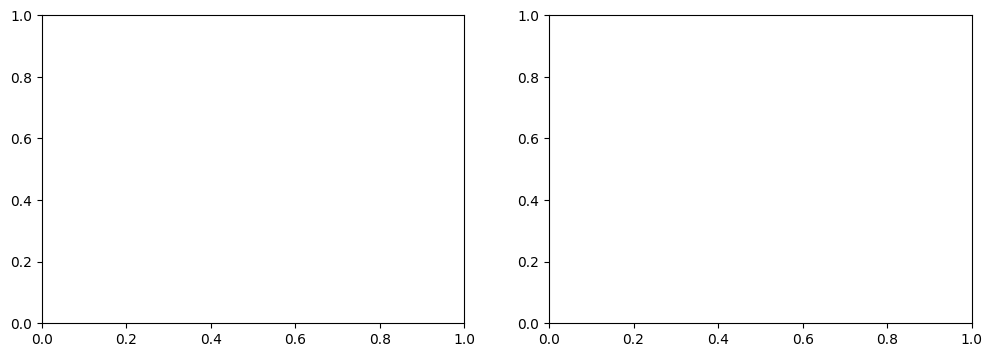

In [48]:
plot_km_subtypes(df_train)